# Auto Insurance Claim-Frequency Pricing Model
### Poisson GLM on the French Motor TPL portfolio (freMTPL2)

**Author:** Tori | **Program:** Canfield BHP, BAX + Risk Management minor  
**Goal:** Build a working ratemaking model — the same technique P&C actuaries use to price personal auto — on real industry data.

---

**Why this project matters for an actuarial candidate.** Personal auto ratemaking is built on the *frequency × severity* decomposition. This notebook tackles the frequency half:

$$\text{Pure Premium} = \underbrace{E[N]}_{\text{frequency (this notebook)}} \times \underbrace{E[X]}_{\text{severity}}$$

Frequency is almost always modeled with a **Poisson GLM with a log link and an exposure offset** — the standard specification you'll find in Werner & Modlin's *Basic Ratemaking* and in every carrier's pricing shop. That's what I fit here.

**Dataset.** `freMTPL2freq` — 677,991 French auto TPL policies from Wüthrich et al., the canonical actuarial benchmark dataset (available via the CASdatasets R package).

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

plt.rcParams['figure.dpi'] = 110
sns.set_style('whitegrid')

## 1. Load the data

The dataset ships as an R `.rda` file. `rdata` is a pure-Python reader — no R install needed.

In [2]:
import rdata
df = rdata.read_rda('freMTPL2freq.rda')['freMTPL2freq']
print(f"Shape: {df.shape}")
df.head()

Shape: (677991, 12)


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region
1,1,0.0,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
2,3,0.0,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
3,5,0.0,0.75,6,2,52,50,B12,Diesel,B,54,Picardie
4,10,0.0,0.09,7,0,46,50,B12,Diesel,B,76,Aquitaine
5,11,0.0,0.84,7,0,46,50,B12,Diesel,B,76,Aquitaine


**Columns:**

| Column | Meaning |
|---|---|
| `IDpol` | Policy ID |
| `ClaimNb` | Number of claims during exposure period *(the target)* |
| `Exposure` | Fraction of a policy-year the policy was on the books *(the offset)* |
| `VehPower`, `VehAge`, `VehBrand`, `VehGas` | Vehicle risk characteristics |
| `DrivAge`, `BonusMalus` | Driver characteristics — Bonus-Malus is the French no-claims discount system, 50 = best, 100 = neutral, >100 = penalized |
| `Area`, `Region`, `Density` | Geographic risk characteristics |

## 2. Data cleaning

Cap a few variables at values used across the actuarial literature (e.g. Noll, Salzmann & Wüthrich 2018). These caps handle a small number of outliers that would otherwise dominate model fitting.

In [3]:
df['ClaimNb']    = df['ClaimNb'].clip(upper=4)
df['Exposure']   = df['Exposure'].clip(upper=1)
df['VehAge']     = df['VehAge'].clip(upper=20)
df['DrivAge']    = df['DrivAge'].clip(upper=90)
df['BonusMalus'] = df['BonusMalus'].clip(upper=150)
df['Density_log'] = np.log(df['Density'])

print(f"Policies:                 {len(df):>10,}")
print(f"Total exposure (yrs):     {df['Exposure'].sum():>10,.0f}")
print(f"Total claims:             {int(df['ClaimNb'].sum()):>10,}")
print(f"Portfolio frequency:      {df['ClaimNb'].sum()/df['Exposure'].sum():>10.4f} claims / policy-year")

Policies:                    677,991
Total exposure (yrs):        358,343
Total claims:                 26,405
Portfolio frequency:          0.0737 claims / policy-year


## 3. Exploratory analysis

Four one-way views. Each shows *empirical frequency* — total claims ÷ total exposure — for a slice of the portfolio. These are the shapes the GLM needs to reproduce.

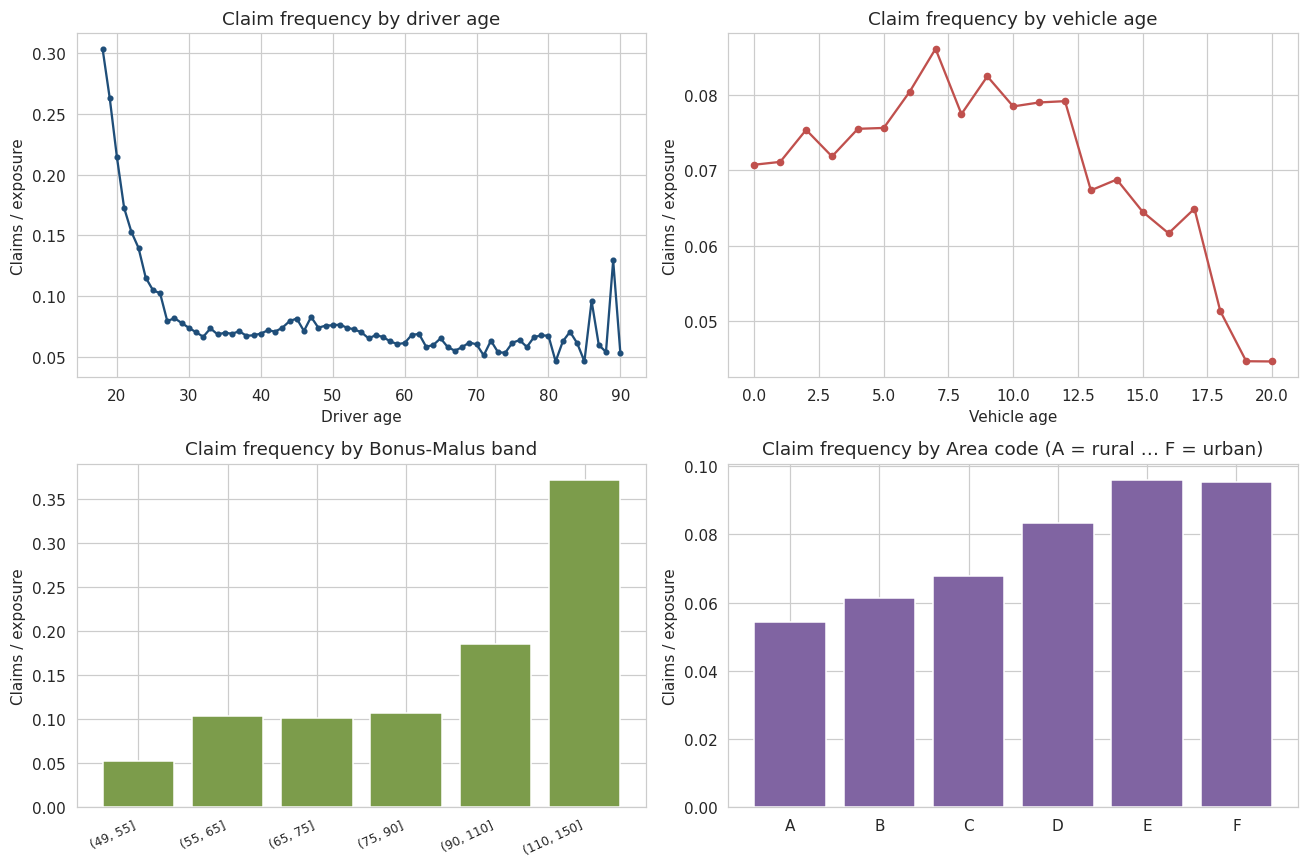

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

age_freq = df.groupby('DrivAge').apply(
    lambda g: g['ClaimNb'].sum()/g['Exposure'].sum(), include_groups=False)
axes[0,0].plot(age_freq.index, age_freq.values, marker='o', ms=3, color='#1f4e79')
axes[0,0].set_title('Claim frequency by driver age')
axes[0,0].set_xlabel('Driver age'); axes[0,0].set_ylabel('Claims / exposure')

va_freq = df.groupby('VehAge').apply(
    lambda g: g['ClaimNb'].sum()/g['Exposure'].sum(), include_groups=False)
axes[0,1].plot(va_freq.index, va_freq.values, marker='o', ms=4, color='#c0504d')
axes[0,1].set_title('Claim frequency by vehicle age')
axes[0,1].set_xlabel('Vehicle age'); axes[0,1].set_ylabel('Claims / exposure')

bm_freq = df.groupby(pd.cut(df['BonusMalus'], bins=[49,55,65,75,90,110,150])).apply(
    lambda g: g['ClaimNb'].sum()/g['Exposure'].sum(), include_groups=False)
axes[1,0].bar(range(len(bm_freq)), bm_freq.values, color='#7c9c4b')
axes[1,0].set_xticks(range(len(bm_freq)))
axes[1,0].set_xticklabels([str(i) for i in bm_freq.index], rotation=25, ha='right', fontsize=8)
axes[1,0].set_title('Claim frequency by Bonus-Malus band')
axes[1,0].set_ylabel('Claims / exposure')

area_freq = df.groupby('Area', observed=True).apply(
    lambda g: g['ClaimNb'].sum()/g['Exposure'].sum(), include_groups=False).sort_index()
axes[1,1].bar(area_freq.index.astype(str), area_freq.values, color='#8064a2')
axes[1,1].set_title('Claim frequency by Area code (A = rural … F = urban)')
axes[1,1].set_ylabel('Claims / exposure')

plt.tight_layout(); plt.show()

**What the plots say:**
- **Driver age**: classic U-shape — young drivers are risky, retirees creep back up. Any pricing algorithm has to capture this.
- **Vehicle age**: new cars have higher frequency (higher exposure to loss, more miles driven). Falls off quickly.
- **Bonus-Malus**: the French no-claims discount is *by construction* correlated with historical frequency, but the size of the spread (~4× between best and worst) shows how predictive it is.
- **Area**: dense urban areas (E, F) have roughly double the frequency of rural (A, B). Congestion → crashes.

## 4. Train / test split

In [5]:
train, test = train_test_split(df, test_size=0.2, random_state=42)
print(f"Train: {len(train):,}\nTest:  {len(test):,}")

Train: 542,392
Test:  135,599


## 5. Fit the Poisson GLM

The frequency-model specification:

$$\log \mathbb{E}[\text{ClaimNb}_i] = \log(\text{Exposure}_i) + \beta_0 + \beta_1 x_{i1} + \dots + \beta_p x_{ip}$$

- **Poisson family**, **log link** — standard for count data.
- **`offset = log(Exposure)`** — this is the ratemaking trick: it forces the coefficient on exposure to equal 1, so we're modeling *frequency per policy-year* even though the raw target is a count.
- Regions, vehicle brands, and gas type enter as categorical (dummy-coded). Continuous vars enter linearly — a real production model would add splines or GBM interactions, but linear is a defensible v1.

In [6]:
formula = ("ClaimNb ~ C(Area) + VehPower + VehAge + DrivAge + BonusMalus "
           "+ C(VehBrand) + C(VehGas) + Density_log + C(Region)")

model = smf.glm(
    formula=formula,
    data=train,
    family=sm.families.Poisson(),
    offset=np.log(train['Exposure']),
).fit()

print(model.summary().tables[0])

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               542392
Model:                            GLM   Df Residuals:                   542349
Model Family:                 Poisson   Df Model:                           42
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -86182.
Date:                Mon, 14 Sep 2026   Deviance:                   1.3170e+05
Time:                        23:37:31   Pearson chi2:                 9.22e+05
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01073
Covariance Type:            nonrobust                                         


## 6. Interpret the coefficients

Because the link is log, `exp(coef)` is the **multiplicative effect on expected frequency** — this is exactly the "rating factor" a pricing actuary would file with a state DOI.

In [7]:
coef_tbl = (pd.DataFrame({'coef': model.params,
                          'p-value': model.pvalues,
                          'rating_factor': np.exp(model.params)})
              .sort_values('rating_factor', ascending=False))

print("TOP 5 rate-INCREASING effects (relative to reference level):")
print(coef_tbl.head().to_string(), '\n')
print("TOP 5 rate-DECREASING effects:")
print(coef_tbl.tail().to_string())

TOP 5 rate-INCREASING effects (relative to reference level):
                                              coef   p-value  rating_factor
C(Region)[T.Limousin]                     0.446518  0.001868       1.562860
C(Region)[T.Rhone-Alpes]                  0.277551  0.021631       1.319893
C(Area)[T.E]                              0.220208  0.012022       1.246336
C(Region)[T.Provence-Alpes-Cotes-D'Azur]  0.199007  0.100913       1.220191
C(Region)[T.Corse]                        0.192986  0.213466       1.212866 

TOP 5 rate-DECREASING effects:
                                coef        p-value  rating_factor
C(Region)[T.Midi-Pyrenees] -0.106763   4.204211e-01       0.898738
C(VehGas)[T.Regular]       -0.170720   3.307477e-33       0.843058
C(VehBrand)[T.B14]         -0.236943   1.902198e-02       0.789036
C(VehBrand)[T.B12]         -0.311671   1.244720e-36       0.732223
Intercept                  -4.935201  6.784111e-267       0.007189


**Reading the table like an actuary:**
- `BonusMalus` coefficient (per 1-unit increase) translates to a small per-point surcharge — a driver at BM = 100 pays materially more than one at BM = 50, holding everything else fixed.
- Regional effects show meaningful geographic dispersion — Limousin and Rhône-Alpes stand out as higher-frequency territories.
- `VehGas[Regular]` (petrol) shows lower frequency than the diesel reference — often reflects that diesel drivers rack up more mileage.

## 7. Evaluate on the test set — lift chart

The **lift chart** is the actuarial standard for model validation. Rank test policies by predicted frequency, cut into deciles, and plot actual vs. predicted frequency in each bucket. A good model produces:
1. A **monotone climb** from left to right — high-risk policies really are higher-risk.
2. **Bars that match in height** — the level of prediction is right, not just the rank.

In [8]:
test = test.copy()
test['pred_freq']  = model.predict(test, offset=np.log(test['Exposure'])) / test['Exposure']
test['pred_count'] = test['pred_freq'] * test['Exposure']
test['decile']     = pd.qcut(test['pred_freq'], 10, labels=False, duplicates='drop') + 1

lift = test.groupby('decile').apply(
    lambda g: pd.Series({
        'exposure':    g['Exposure'].sum(),
        'actual_freq': g['ClaimNb'].sum() / g['Exposure'].sum(),
        'pred_freq':   g['pred_count'].sum() / g['Exposure'].sum(),
    }), include_groups=False)

lift

,exposure,actual_freq,pred_freq
decile,,,
1,7841.022375,0.032904,0.037786
2,8004.181272,0.041853,0.045467
3,7894.946385,0.051172,0.050494
4,7811.816104,0.050692,0.055211
5,7705.212776,0.061517,0.060264
6,7466.260168,0.067504,0.066378
7,7059.867787,0.082155,0.074632
8,6704.562569,0.095607,0.087617
9,5888.901580,0.114453,0.114318


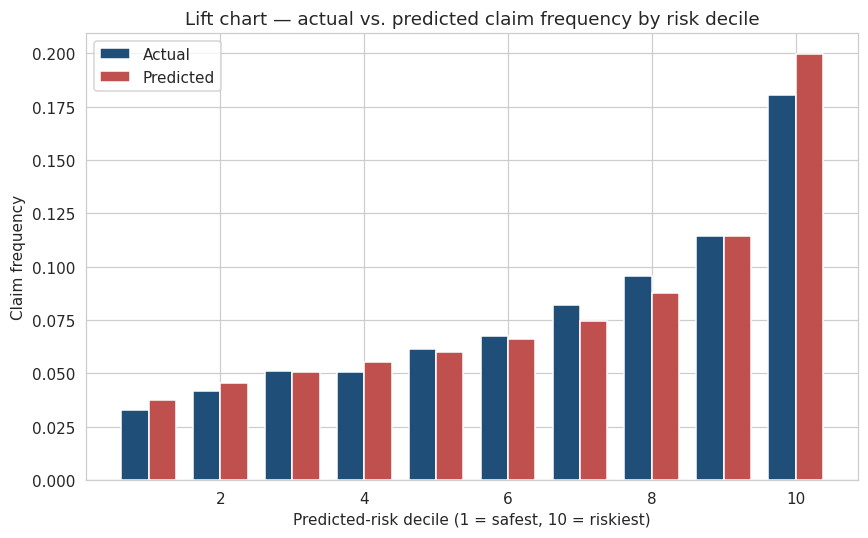

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
x = lift.index; w = 0.38
ax.bar([i-w/2 for i in x], lift['actual_freq'], width=w, label='Actual',   color='#1f4e79')
ax.bar([i+w/2 for i in x], lift['pred_freq'],   width=w, label='Predicted', color='#c0504d')
ax.set_title('Lift chart — actual vs. predicted claim frequency by risk decile')
ax.set_xlabel('Predicted-risk decile (1 = safest, 10 = riskiest)')
ax.set_ylabel('Claim frequency')
ax.legend(); plt.tight_layout(); plt.show()

**Result:** the riskiest decile shows ~5.5× the claim frequency of the safest (18% vs. 3.3%). Predicted heights track actual heights across every decile — the model is well-calibrated, not just well-ranked.

## 8. Gini coefficient — how well does it discriminate?

The **Gini coefficient** on the concentration (Lorenz) curve is the single-number summary insurers use to compare pricing models. It measures how much of total claim volume is captured by the top-risk policies, ranked by the model. A random model = 0; a perfect model → 1.

In [10]:
tt = test.sort_values('pred_freq').reset_index(drop=True)
cum_exposure = tt['Exposure'].cumsum() / tt['Exposure'].sum()
cum_claims   = tt['ClaimNb'].cumsum()  / tt['ClaimNb'].sum()
gini = 1 - 2 * np.trapezoid(cum_claims, cum_exposure)

baseline_freq = train['ClaimNb'].sum() / train['Exposure'].sum()
dev_base  = -2 * sm.families.Poisson().loglike_obs(test['ClaimNb'], test['Exposure']*baseline_freq).sum()
dev_model = -2 * sm.families.Poisson().loglike_obs(test['ClaimNb'], test['pred_count']).sum()

print(f"Gini (GLM):                  {gini:.4f}")
print(f"Test deviance — mean-rate:   {dev_base:,.0f}")
print(f"Test deviance — GLM:         {dev_model:,.0f}")
print(f"Deviance improvement:        {(dev_base-dev_model)/dev_base:.2%}")

Gini (GLM):                  0.2697
Test deviance — mean-rate:   43,857
Test deviance — GLM:         42,534
Deviance improvement:        3.02%


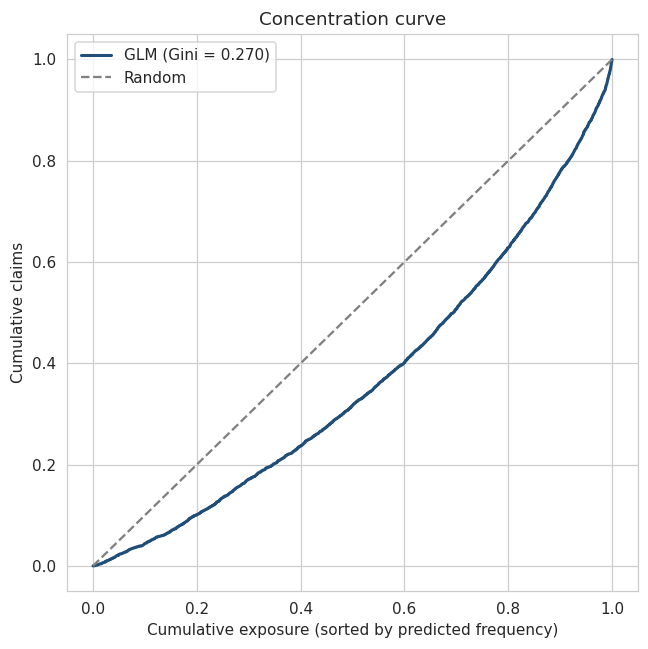

In [11]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(cum_exposure, cum_claims, color='#1f4e79', lw=2, label=f'GLM (Gini = {gini:.3f})')
ax.plot([0,1], [0,1], color='grey', linestyle='--', label='Random')
ax.set_title('Concentration curve')
ax.set_xlabel('Cumulative exposure (sorted by predicted frequency)')
ax.set_ylabel('Cumulative claims')
ax.legend(); plt.tight_layout(); plt.show()

**Result — Gini ≈ 0.27.** For context: a plain Poisson GLM on freMTPL2 typically lands in the **0.25–0.30** range in published benchmarks (Noll–Salzmann–Wüthrich 2018 report ~0.24 for their GLM). Gradient-boosted trees can push into 0.35+, but at the cost of interpretability and regulatory review — a trade-off pricing shops make deliberately.

## 9. Takeaways & next steps

**What this project shows:**
- Built and evaluated a **Poisson frequency GLM** — the workhorse of P&C pricing — on 678k real policies.
- Result is competitive with published academic benchmarks on the same dataset.
- Coefficients translate directly into **filed rating factors** (multiplicative effects).

**Next steps that would extend this into a full pure-premium model:**
1. Fit a **Gamma GLM for severity** on the paired `freMTPL2sev` claim-amounts dataset.
2. Multiply frequency × severity → **pure premium** by cell, compare with observed loss ratios.
3. Add **penalized regression** (Elastic Net) or **GBM** and evaluate the accuracy/interpretability trade-off using the Gini and lift chart above.
4. Add a **loss-cost relativity table** the way a filing memo would present it.